# Principle Component Aalysis

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
import os
os.chdir("E:/Vishal_Adesh/CDAC/Machine Learning/Datasets")

In [2]:
df = pd.read_csv("milk.csv",index_col=0)
df.head()

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10


In [3]:
df.info()

<class 'pandas.DataFrame'>
Index: 25 entries, HORSE to DOLPHIN
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   water    25 non-null     float64
 1   protein  25 non-null     float64
 2   fat      25 non-null     float64
 3   lactose  25 non-null     float64
 4   ash      25 non-null     float64
dtypes: float64(5)
memory usage: 1.2+ KB


In [4]:
df

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,90.1,2.6,1.0,6.9,0.35
ORANGUTAN,88.5,1.4,3.5,6.0,0.24
MONKEY,88.4,2.2,2.7,6.4,0.18
DONKEY,90.3,1.7,1.4,6.2,0.40
HIPPO,90.4,0.6,4.5,4.4,0.10
CAMEL,87.7,3.5,3.4,4.8,0.71
BISON,86.9,4.8,1.7,5.7,0.90
BUFFALO,82.1,5.9,7.9,4.7,0.78
GUINEA PIG,81.9,7.4,7.2,2.7,0.85


In [5]:
df.isnull().sum().sum()

np.int64(0)

In [6]:
scaler = StandardScaler().set_output(transform='pandas')
scl_df = scaler.fit_transform(df)
scl_df

,water,protein,fat,lactose,ash
Animal,,,,,
HORSE,0.948806,-1.009291,-0.903208,1.542217,-1.037554
ORANGUTAN,0.821407,-1.344603,-0.660619,1.040773,-1.259945
MONKEY,0.813445,-1.121062,-0.738247,1.263637,-1.381249
DONKEY,0.964731,-1.260775,-0.864394,1.152205,-0.936467
HIPPO,0.972694,-1.568145,-0.563583,0.149319,-1.542988
CAMEL,0.757707,-0.757806,-0.670322,0.372182,-0.309730
BISON,0.694008,-0.394551,-0.835283,0.873626,0.074400
BUFFALO,0.311810,-0.087181,-0.233662,0.316466,-0.168208
GUINEA PIG,0.295885,0.331959,-0.301587,-0.797852,-0.026687


In [7]:
pc = PCA().set_output(transform='pandas')
pca_data = pc.fit_transform(scl_df)

In [8]:
pca_data

,pca0,pca1,pca2,pca3,pca4
Animal,,,,,
HORSE,2.435175,-0.231478,0.330150,0.307664,0.048184
ORANGUTAN,2.258736,-0.693148,0.029035,-0.081057,-0.000532
MONKEY,2.335861,-0.663328,0.101257,0.247997,0.010109
DONKEY,2.318677,-0.273815,0.109881,-0.092873,-0.006769
HIPPO,2.060294,-1.019199,-0.762436,-0.510091,0.029382
CAMEL,1.301536,0.137303,-0.198742,-0.282160,-0.014668
BISON,1.282742,0.622667,0.253785,0.065148,-0.044486
BUFFALO,0.505068,0.088235,0.008383,0.133774,0.083806
GUINEA PIG,-0.255502,0.287373,-0.881857,-0.013100,-0.016484


In [9]:
df.shape, pca_data.shape

((25, 5), (25, 5))

In [10]:
sigma = scl_df.cov()
sigma

,water,protein,fat,lactose,ash
water,1.041667,-0.787249,-1.022781,0.899883,-0.446972
protein,-0.787249,1.041667,0.684918,-0.877285,0.839718
fat,-1.022781,0.684918,1.041667,-0.876081,0.338185
lactose,0.899883,-0.877285,-0.876081,1.041667,-0.624630
ash,-0.446972,0.839718,0.338185,-0.624630,1.041667


In [11]:
pca_data.var()

pca0    4.040412
pca1    0.924372
pca2    0.134291
pca3    0.102689
pca4    0.006570
dtype: float64

In [12]:
values, vectors  = np.linalg.eig(sigma)
values

array([4.0404117 +0.j, 0.92437238+0.j, 0.00656977+0.j, 0.13429088+0.j,
       0.1026886 +0.j])

In [13]:
vectors

array([[-0.47294379+0.j,  0.35285509+0.j, -0.70967042+0.j,
         0.36921298+0.j,  0.10893632+0.j],
       [ 0.46657047+0.j,  0.32094099+0.j, -0.1930657 +0.j,
         0.15196177+0.j, -0.78672876+0.j],
       [ 0.44868269+0.j, -0.47603724+0.j, -0.66831106+0.j,
        -0.30699163+0.j,  0.17660367+0.j],
       [-0.48289116+0.j,  0.05951482+0.j, -0.11159049+0.j,
        -0.77642589+0.j, -0.38468756+0.j],
       [ 0.35232959+0.j,  0.73643513+0.j,  0.00118661+0.j,
        -0.378825  +0.j,  0.43590982+0.j]])

In [14]:
total_var = pca_data.var().sum()
total_var

np.float64(5.208333333333338)

In [15]:
pc.explained_variance_

array([4.0404117 , 0.92437238, 0.13429088, 0.1026886 , 0.00656977])

##### analyze how much variance each individual component explains

In [16]:
pc.explained_variance_ratio_

array([0.77575905, 0.1774795 , 0.02578385, 0.01971621, 0.0012614 ])

##### Having all principal components allows you to perform inverse transformation 

In [18]:
pc.inverse_transform(pca_data)

array([[ 0.94880628, -1.00929078, -0.90320785,  1.54221661, -1.03755398],
       [ 0.82140698, -1.34460333, -0.66061872,  1.04077335, -1.25994474],
       [ 0.81344452, -1.12106163, -0.73824724,  1.26363702, -1.38124879],
       [ 0.96473119, -1.26077519, -0.86439359,  1.15220518, -0.93646727],
       [ 0.97269365, -1.56814503, -0.56358307,  0.14931866, -1.54298752],
       [ 0.75770733, -0.75780637, -0.67032229,  0.37218233, -0.30972968],
       [ 0.69400768, -0.3945511 , -0.83528289,  0.87362559,  0.07439982],
       [ 0.31180978, -0.08718126, -0.23366185,  0.31646641, -0.16820828],
       [ 0.29588487,  0.33195943, -0.30158681, -0.79785195, -0.02668689],
       [ 0.2719975 ,  1.08641267, -0.38891889,  0.14931866, -0.22886031],
       [ 0.2719975 ,  0.10841772, -0.42773316,  0.42789825,  0.13505184],
       [ 0.66215786, -0.64603552, -0.68972942,  0.81790968, -0.1277736 ],
       [ 0.94084382, -1.17694705, -0.82557933,  0.76219376, -0.79494588],
       [ 0.36754698,  0.24813129, -0.5

##### proportion of var

In [19]:
pca_data.var()/total_var

pca0    0.775759
pca1    0.177479
pca2    0.025784
pca3    0.019716
pca4    0.001261
dtype: float64

##### % var explained

In [20]:
pc.explained_variance_ratio_*100

array([77.57590469, 17.74794969,  2.57838496,  1.97162103,  0.12613963])

In [21]:
[f"{val * 100:.2f}%" for val in pc.explained_variance_ratio_]

['77.58%', '17.75%', '2.58%', '1.97%', '0.13%']

##### cummulative sum of % var [ first 2 col explained/contains 95 % of your data]

In [22]:
np.cumsum(pc.explained_variance_ratio_*100)

array([ 77.57590469,  95.32385438,  97.90223934,  99.87386037,
       100.        ])

In [23]:
pca_data[['pca0','pca1']]

,pca0,pca1
Animal,,
HORSE,2.435175,-0.231478
ORANGUTAN,2.258736,-0.693148
MONKEY,2.335861,-0.663328
DONKEY,2.318677,-0.273815
HIPPO,2.060294,-1.019199
CAMEL,1.301536,0.137303
BISON,1.282742,0.622667
BUFFALO,0.505068,0.088235
GUINEA PIG,-0.255502,0.287373


## PCA - BreastCancer

In [24]:
wisc = pd.read_csv("../Day5/BreastCancer.csv",index_col=0)
wisc

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign
...,...,...,...,...,...,...,...,...,...,...
1369821,10,10,10,10,5,10,10,10,7,Malignant
1371026,5,10,10,10,4,10,5,6,3,Malignant
1371920,5,1,1,1,2,1,3,2,1,Benign


In [25]:
X, y = wisc.drop("Class",axis=1),wisc["Class"]
X

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses
Code,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1
63375,9,1,2,6,4,10,7,7,2
76389,10,4,7,2,2,8,6,1,1
95719,6,10,10,10,8,10,7,10,7
128059,1,1,1,1,2,5,5,1,1
...,...,...,...,...,...,...,...,...,...
1369821,10,10,10,10,5,10,10,10,7
1371026,5,10,10,10,4,10,5,6,3
1371920,5,1,1,1,2,1,3,2,1


In [26]:
X_scl = scaler.fit_transform(X)

In [27]:
X_scl

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses
Code,,,,,,,,,
61634,0.206936,0.283845,-0.069850,-0.633247,-0.549561,-0.425655,-0.590067,0.043601,-0.343912
63375,1.628538,-0.699995,-0.406574,1.119088,0.354305,1.794739,1.461957,1.354454,0.239570
76389,1.983939,0.283845,1.277048,-0.282780,-0.549561,1.239641,1.051552,-0.611825,-0.343912
95719,0.562336,2.251526,2.287222,2.520955,2.162039,1.794739,1.461957,2.337594,3.156977
128059,-1.214667,-0.699995,-0.743299,-0.633247,-0.549561,0.406993,0.641147,-0.611825,-0.343912
...,...,...,...,...,...,...,...,...,...
1369821,1.983939,2.251526,2.287222,2.520955,0.806239,1.794739,2.693171,2.337594,3.156977
1371026,0.206936,2.251526,2.287222,2.520955,0.354305,1.794739,0.641147,1.026741,0.823051
1371920,0.206936,-0.699995,-0.743299,-0.633247,-0.549561,-0.703204,-0.179662,-0.284112,-0.343912


In [28]:
pc = PCA().set_output(transform='pandas')
pca_data = pc.fit_transform(X_scl)
pca_data

,pca0,pca1,pca2,pca3,pca4,pca5,pca6,pca7,pca8
Code,,,,,,,,,
61634,-0.661561,-0.168216,0.583962,-0.439347,-0.230526,0.130653,-0.097528,0.541727,0.328081
63375,2.178759,-0.693348,0.432389,1.192376,-1.074153,-0.442691,-0.702441,-1.787781,-0.244667
76389,1.404956,-1.364750,1.761714,0.878367,0.013219,-0.517801,0.835375,0.408381,-0.565653
95719,6.073098,1.994961,-1.081435,0.237234,-0.141189,0.019790,-0.355352,0.444035,-0.062628
128059,-1.237518,-0.370332,-0.823064,0.473932,-0.127604,-1.151372,0.508269,-0.344131,0.029906
...,...,...,...,...,...,...,...,...,...
1369821,6.473443,1.285709,0.048059,0.936819,-1.446932,0.152226,0.731058,0.235807,-0.042668
1371026,4.097345,-0.215083,-1.078721,0.912918,0.027151,0.599090,-0.276698,1.705969,0.099999
1371920,-1.351669,-0.095164,0.536224,-0.120275,-0.359013,0.101649,0.178219,-0.452815,0.002252


In [29]:
pca_data.var()

pca0    5.899333
pca1    0.777475
pca2    0.539624
pca3    0.462914
pca4    0.380272
pca5    0.305723
pca6    0.296021
pca7    0.262712
pca8    0.088819
dtype: float64

In [30]:
pc.explained_variance_ratio_*100

array([65.45437483,  8.62625123,  5.98724547,  5.13612665,  4.21920122,
        3.39206535,  3.28441735,  2.91485025,  0.98546764])

In [31]:
[f"{val * 100:.2f}%" for val in pc.explained_variance_ratio_]

['65.45%',
 '8.63%',
 '5.99%',
 '5.14%',
 '4.22%',
 '3.39%',
 '3.28%',
 '2.91%',
 '0.99%']

In [32]:
np.cumsum(pc.explained_variance_ratio_*100)

array([ 65.45437483,  74.08062606,  80.06787153,  85.20399818,
        89.42319941,  92.81526476,  96.09968211,  99.01453236,
       100.        ])

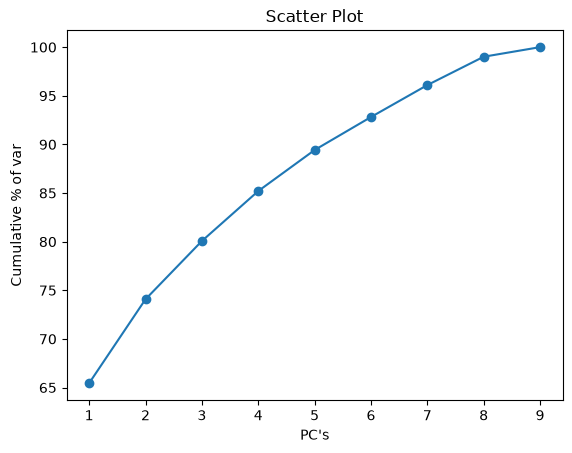

In [33]:
plt.scatter(range(1,10),np.cumsum(pc.explained_variance_ratio_*100))
plt.plot(range(1,10), np.cumsum(pc.explained_variance_ratio_*100))
plt.title("Scatter Plot")
plt.xlabel("PC's")
plt.ylabel("Cumulative % of var")
plt.show()

In [34]:
data = pd.DataFrame({
    'pca0': pca_data['pca0'],
    'pca1': pca_data['pca1'],
    'Class': wisc['Class']
})
data

,pca0,pca1,Class
Code,,,
61634,-0.661561,-0.168216,Benign
63375,2.178759,-0.693348,Malignant
76389,1.404956,-1.364750,Malignant
95719,6.073098,1.994961,Malignant
128059,-1.237518,-0.370332,Benign
...,...,...,...
1369821,6.473443,1.285709,Malignant
1371026,4.097345,-0.215083,Malignant
1371920,-1.351669,-0.095164,Benign


In [35]:
import seaborn as sns

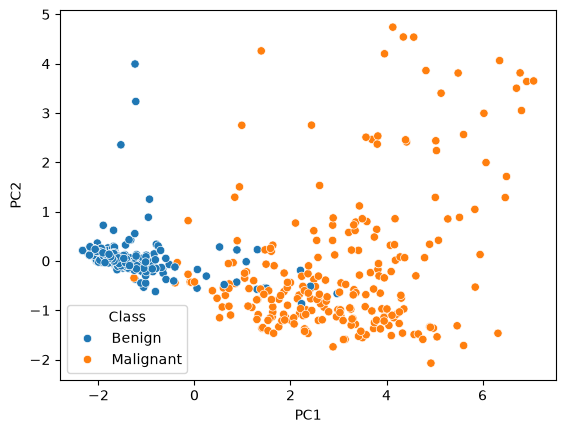

In [36]:
sns.scatterplot(x=data["pca0"],y=data["pca1"], hue=data["Class"])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# SVM ON Wisc DATA

In [86]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

In [87]:
wisc

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign
...,...,...,...,...,...,...,...,...,...,...
1369821,10,10,10,10,5,10,10,10,7,Malignant
1371026,5,10,10,10,4,10,5,6,3,Malignant
1371920,5,1,1,1,2,1,3,2,1,Benign


In [88]:
X, y = wisc.drop("Class",axis=1), wisc["Class"]
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=26,test_size=0.3,stratify=y)

In [89]:
svm = SVC(kernel="linear")
svm.fit(X_train,y_train)
y_pred = svm.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant")

0.9324324324324325

#### 

# SVM ON PCA DATA

In [90]:
pipe = Pipeline([("SCL",scaler),("PCA",pc),("SVM",svm)])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant")

0.9324324324324325

In [104]:
pc = PCA(n_components=2).set_output(transform='pandas')
pc.fit_transform(X)

,pca0,pca1,pca2
Code,,,
61634,-1.578410,-1.250952,1.697742
63375,6.685459,4.121834,0.712446
76389,4.899082,4.102293,5.168775
95719,16.593063,-1.952937,-3.776265
128059,-3.294449,2.838637,-2.187085
...,...,...,...
1369821,17.913217,-1.209653,-0.541525
1371026,12.785727,1.351164,-3.484572
1371920,-4.081265,-0.575422,1.596055


In [106]:
pc = PCA(n_components=2).set_output(transform='pandas')
pipe = Pipeline([("SCL",scaler),("PCA",pc),("SVM",svm)])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant")

0.9395973154362416

In [107]:
pc = PCA(n_components=3).set_output(transform='pandas')
pipe = Pipeline([("SCL",scaler),("PCA",pc),("SVM",svm)])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant")

0.9395973154362416

In [108]:
pc = PCA(n_components=4).set_output(transform='pandas')
pipe = Pipeline([("SCL",scaler),("PCA",pc),("SVM",svm)])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant")

0.9530201342281879

In [109]:
pc = PCA(n_components=5).set_output(transform='pandas')
pipe = Pipeline([("SCL",scaler),("PCA",pc),("SVM",svm)])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant")

0.9530201342281879

In [110]:
pc = PCA(n_components=6).set_output(transform='pandas')
pipe = Pipeline([("SCL",scaler),("PCA",pc),("SVM",svm)])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant")

0.9459459459459459

In [111]:
pc = PCA(n_components=7).set_output(transform='pandas')
pipe = Pipeline([("SCL",scaler),("PCA",pc),("SVM",svm)])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
f1_score(y_test,y_pred,pos_label="Malignant")

0.9387755102040817